In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

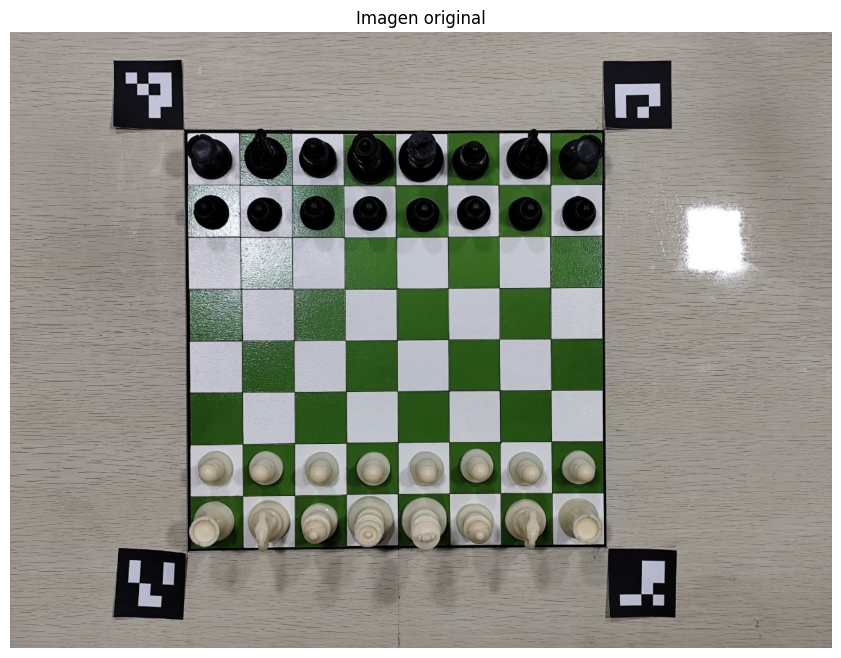

In [73]:
IMAGE_PATH = r"C:\Users\User\Desktop\Brazo Robotico\Dataset\Tableros\photo_1_2026-05-18_22-29-53.jpg"

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError("No se pudo cargar la imagen. Revisa la ruta.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.title("Imagen original")
plt.axis("off")
plt.show()

In [74]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")

    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)

    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]      # superior izquierda
    ordenados[2] = pts[np.argmax(suma)]      # inferior derecha
    ordenados[1] = pts[np.argmin(resta)]     # superior derecha
    ordenados[3] = pts[np.argmax(resta)]     # inferior izquierda

    return ordenados

In [75]:
def detectar_aruco(imagen_bgr, mostrar=True):
    img = imagen_bgr.copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Cambia este diccionario si tus ArUco son de otro tipo
    aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_50)
    parameters = cv2.aruco.DetectorParameters()

    detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)
    corners, ids, rejected = detector.detectMarkers(gray)

    if ids is None or len(ids) < 4:
        print(f"Marcadores detectados: {0 if ids is None else len(ids)}")
        print("No se detectaron al menos 4 marcadores ArUco.")
        return None, None

    if mostrar:
        debug = img.copy()
        cv2.aruco.drawDetectedMarkers(debug, corners, ids)

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(debug, cv2.COLOR_BGR2RGB))
        plt.title("Marcadores ArUco detectados")
        plt.axis("off")
        plt.show()

        print("IDs detectados:", ids.flatten())

    return corners, ids

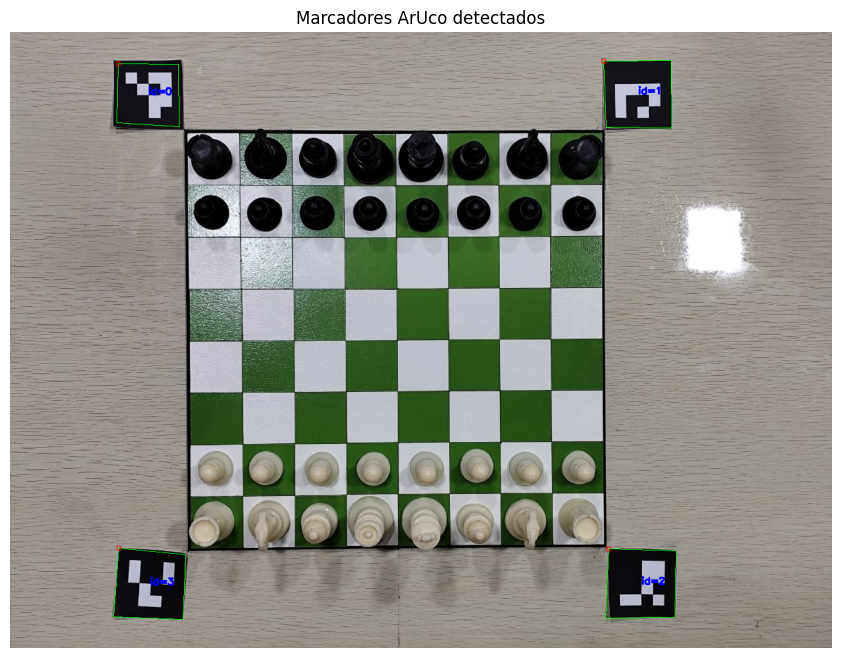

IDs detectados: [2 3 1 0]


In [76]:
aruco_corners, aruco_ids = detectar_aruco(img, mostrar=True)

In [77]:
def obtener_esquinas_tablero_desde_aruco(corners, ids, mostrar=True, imagen_bgr=None):
    datos = []

    for marker_corners, marker_id in zip(corners, ids.flatten()):
        pts = marker_corners.reshape(4, 2)

        centro = pts.mean(axis=0)

        datos.append({
            "id": marker_id,
            "corners": pts,
            "centro": centro
        })

    # Ordenamos por posición vertical
    datos_ordenados_y = sorted(datos, key=lambda d: d["centro"][1])

    # Los 2 de arriba y los 2 de abajo
    arriba = datos_ordenados_y[:2]
    abajo = datos_ordenados_y[2:]

    # Ordenamos cada grupo por posición horizontal
    arriba = sorted(arriba, key=lambda d: d["centro"][0])
    abajo = sorted(abajo, key=lambda d: d["centro"][0])

    marker_tl = arriba[0]   # superior izquierdo
    marker_tr = arriba[1]   # superior derecho
    marker_bl = abajo[0]    # inferior izquierdo
    marker_br = abajo[1]    # inferior derecho

    # Cada marcador tiene sus esquinas en este orden:
    # 0 = superior izquierda
    # 1 = superior derecha
    # 2 = inferior derecha
    # 3 = inferior izquierda

    board_tl = marker_tl["corners"][2]  # esquina interna
    board_tr = marker_tr["corners"][3]  # esquina interna
    board_br = marker_br["corners"][0]  # esquina interna
    board_bl = marker_bl["corners"][1]  # esquina interna

    board_corners = np.array([
        board_tl,
        board_tr,
        board_br,
        board_bl
    ], dtype="float32")

    board_corners = ordenar_puntos(board_corners)

    if mostrar and imagen_bgr is not None:
        debug = imagen_bgr.copy()

        for punto in board_corners:
            x, y = punto.astype(int)
            cv2.circle(debug, (x, y), 10, (0, 0, 255), -1)

        cv2.polylines(
            debug,
            [board_corners.astype(int)],
            isClosed=True,
            color=(0, 255, 0),
            thickness=4
        )

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(debug, cv2.COLOR_BGR2RGB))
        plt.title("Esquinas del tablero calculadas desde ArUco")
        plt.axis("off")
        plt.show()

    return board_corners

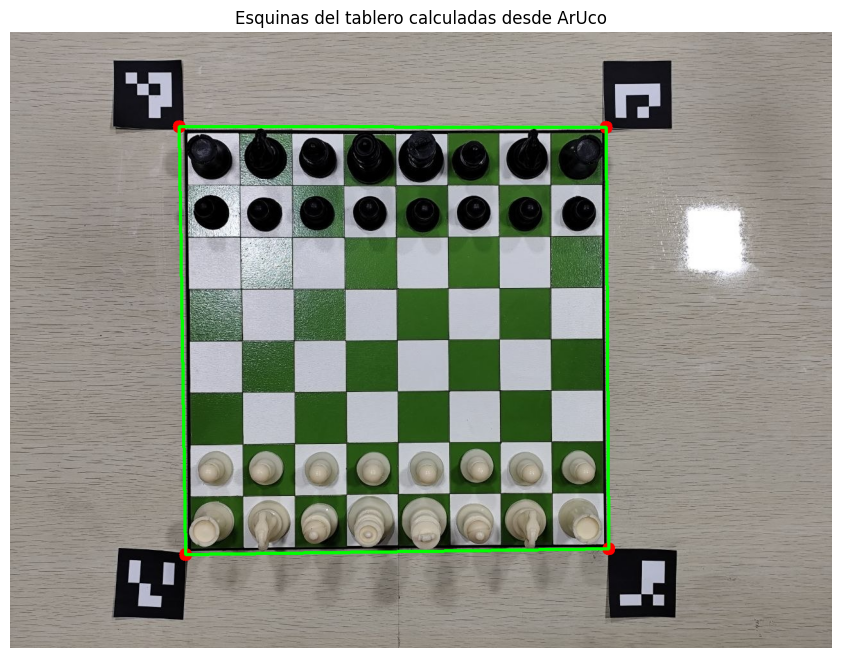

Esquinas del tablero:
[[263. 147.]
 [928. 148.]
 [932. 805.]
 [273. 814.]]


In [78]:
corners_tablero = obtener_esquinas_tablero_desde_aruco(
    aruco_corners,
    aruco_ids,
    mostrar=True,
    imagen_bgr=img
)

print("Esquinas del tablero:")
print(corners_tablero)

In [61]:
def enderezar_tablero(imagen_bgr, corners, size=800):
    corners = ordenar_puntos(corners)

    destino = np.array([
        [0, 0],
        [size - 1, 0],
        [size - 1, size - 1],
        [0, size - 1]
    ], dtype="float32")

    matriz = cv2.getPerspectiveTransform(corners, destino)

    tablero_warp = cv2.warpPerspective(
        imagen_bgr,
        matriz,
        (size, size)
    )

    return tablero_warp

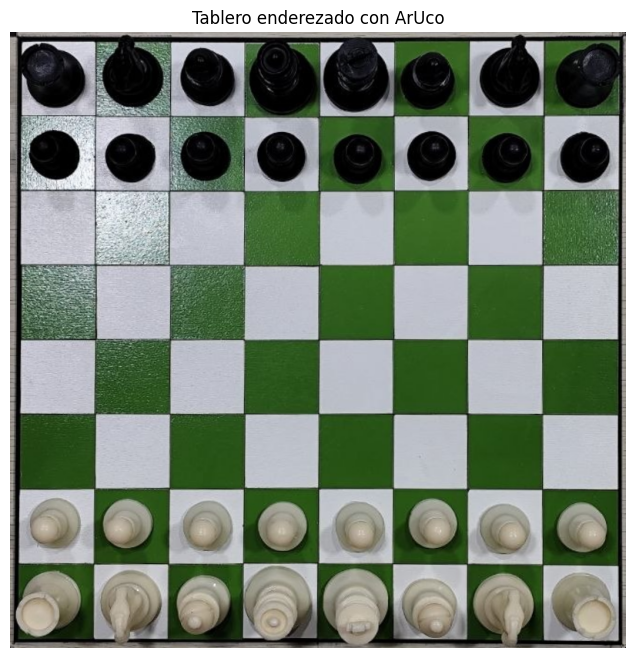

In [46]:
tablero_recto = enderezar_tablero(img, corners_tablero, size=800)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(tablero_recto, cv2.COLOR_BGR2RGB))
plt.title("Tablero enderezado con ArUco")
plt.axis("off")
plt.show()

In [47]:
def dibujar_grid(tablero_bgr, n=8):
    img_grid = tablero_bgr.copy()
    h, w = img_grid.shape[:2]

    cell_w = w // n
    cell_h = h // n

    for i in range(n + 1):
        x = i * cell_w
        y = i * cell_h

        cv2.line(img_grid, (x, 0), (x, h), (255, 0, 0), 2)
        cv2.line(img_grid, (0, y), (w, y), (255, 0, 0), 2)

    return img_grid

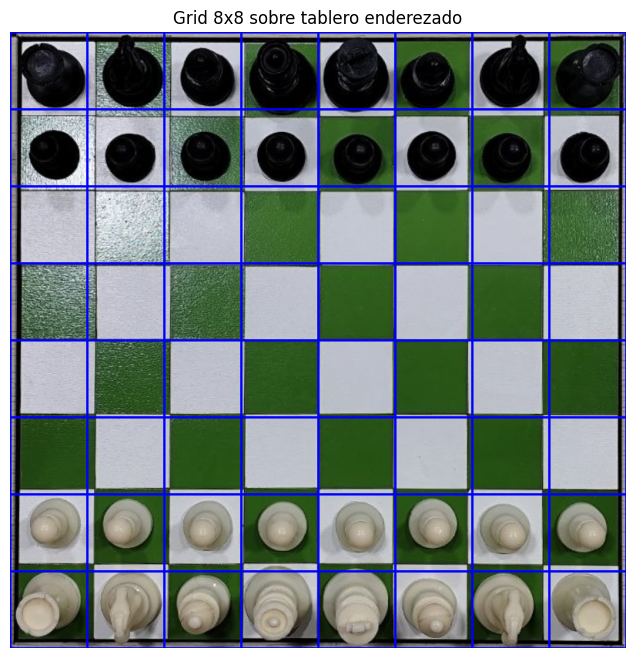

In [48]:
grid_img = dibujar_grid(tablero_recto)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB))
plt.title("Grid 8x8 sobre tablero enderezado")
plt.axis("off")
plt.show()

In [ ]:
def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]

    return columnas[col] + filas[fila]

In [ ]:
def segmentar_casillas_con_notacion(tablero_bgr, output_dir="casillas_aruco", n=8):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n

    casillas = []

    for fila in range(n):
        for col in range(n):
            y1 = fila * cell_h
            y2 = (fila + 1) * cell_h
            x1 = col * cell_w
            x2 = (col + 1) * cell_w

            casilla = tablero_bgr[y1:y2, x1:x2]

            nombre = nombre_casilla_ajedrez(fila, col)
            ruta = output_dir / f"{nombre}.jpg"

            cv2.imwrite(str(ruta), casilla)

            casillas.append({
                "casilla": nombre,
                "fila": fila,
                "columna": col,
                "imagen": casilla,
                "ruta": ruta
            })

    return casillas

In [ ]:
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

for item in casillas:
    fila = item["fila"]
    col = item["columna"]
    nombre = item["casilla"]

    casilla_rgb = cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB)

    axes[fila, col].imshow(casilla_rgb)
    axes[fila, col].set_title(nombre, fontsize=8)
    axes[fila, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
INPUT_DIR = Path("fotos_tableros_aruco")
OUTPUT_DIR = Path("dataset_casillas_aruco")
BOARD_SIZE = 800

EXTENSIONES = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

imagenes = []

for ext in EXTENSIONES:
    imagenes.extend(INPUT_DIR.glob(ext))

print(f"Imágenes encontradas: {len(imagenes)}")

procesadas = 0
fallidas = 0

for idx, img_path in enumerate(imagenes, start=1):
    print(f"\nProcesando {idx}/{len(imagenes)}: {img_path.name}")

    img = cv2.imread(str(img_path))

    if img is None:
        print("No se pudo leer la imagen.")
        fallidas += 1
        continue

    try:
        aruco_corners, aruco_ids = detectar_aruco(img, mostrar=False)

        if aruco_corners is None or aruco_ids is None:
            print("No se detectaron los 4 ArUco.")
            fallidas += 1
            continue

        corners_tablero = obtener_esquinas_tablero_desde_aruco(
            aruco_corners,
            aruco_ids,
            mostrar=False,
            imagen_bgr=None
        )

        tablero_recto = enderezar_tablero(
            img,
            corners_tablero,
            size=BOARD_SIZE
        )

        nombre_base = img_path.stem
        carpeta_tablero = OUTPUT_DIR / nombre_base
        carpeta_tablero.mkdir(parents=True, exist_ok=True)

        cv2.imwrite(str(carpeta_tablero / "tablero_enderezado.jpg"), tablero_recto)

        casillas = segmentar_casillas_con_notacion(
            tablero_recto,
            output_dir=carpeta_tablero / "casillas",
            n=8
        )

        print(f"Guardadas {len(casillas)} casillas.")

        procesadas += 1

    except Exception as e:
        print(f"Error procesando {img_path.name}: {e}")
        fallidas += 1

print("\n===================================")
print("PROCESO TERMINADO")
print("===================================")
print(f"Imágenes procesadas correctamente: {procesadas}")
print(f"Imágenes fallidas: {fallidas}")
print(f"Dataset guardado en: {OUTPUT_DIR.resolve()}")